<a href="https://colab.research.google.com/github/Roshan2008-M/DSA0404_FUNDAMENTALS_OF_DATASCIENCE_-1922524057-/blob/main/LAB%20PROGRAM%20_16%20AND%2017%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import re
from collections import Counter
from google.colab import files

# Upload the dataset
uploaded = files.upload()

# Read the uploaded Excel file
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name)

# Extract customer reviews
text = " ".join(df["text"].dropna().astype(str)).lower()

# Extract words
words = re.findall(r'\b[a-z]+\b', text)

# Calculate word frequency
word_frequency = Counter(words)

# Display word frequency
print("Word Frequency Distribution")
print("--------------------------------")

for word, count in word_frequency.most_common(20):
    print(word, ":", count)

    print("--------------------------------")
    print("Total Words:", len(words))
    print("Unique Words:", len(word_frequency))


Saving 16bbc-text.xlsx to 16bbc-text.xlsx
Word Frequency Distribution
--------------------------------
the : 52636
--------------------------------
Total Words: 855598
Unique Words: 27877
to : 25113
--------------------------------
Total Words: 855598
Unique Words: 27877
of : 20008
--------------------------------
Total Words: 855598
Unique Words: 27877
and : 18611
--------------------------------
Total Words: 855598
Unique Words: 27877
a : 18323
--------------------------------
Total Words: 855598
Unique Words: 27877
in : 17725
--------------------------------
Total Words: 855598
Unique Words: 27877
s : 9070
--------------------------------
Total Words: 855598
Unique Words: 27877
for : 8945
--------------------------------
Total Words: 855598
Unique Words: 27877
is : 8555
--------------------------------
Total Words: 855598
Unique Words: 27877
that : 8257
--------------------------------
Total Words: 855598
Unique Words: 27877
it : 7893
--------------------------------
Total Words: 85

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Saving 17Mall_Customers.csv to 17Mall_Customers (1).csv
Using column 'Gender' for text analysis.
Enter the number of top words: 10

Top 10 Most Frequent Words
--------------------------------
female : 112
male : 88


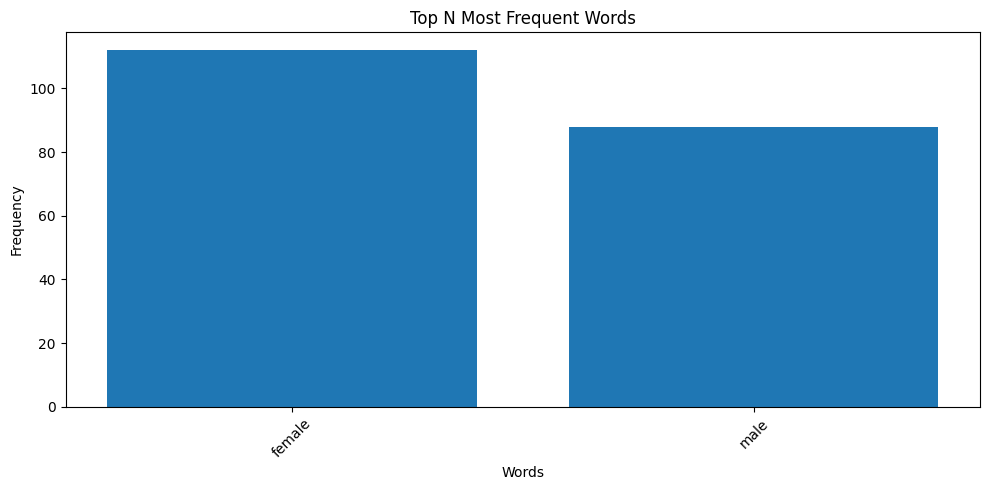

In [4]:
import pandas as pd
import re
import nltk
import matplotlib.pyplot as plt
from collections import Counter
from google.colab import files
from nltk.corpus import stopwords

# Download stopwords
nltk.download('stopwords')

# Upload dataset
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

# Load dataset
if file_name.endswith('.xlsx'):
    df = pd.read_excel(file_name)
else:
    try:
        df = pd.read_csv(file_name, encoding='utf-8')
    except UnicodeDecodeError:
        df = pd.read_csv(file_name, encoding='latin-1')

# Dynamically search for a text column
candidate_columns = ['text', 'Review Text', 'review', 'body', 'Message', 'Gender']
column_name = None

for col in candidate_columns:
    if col in df.columns:
        column_name = col
        break

# If none of the candidates match, fallback to the first text-like column
if column_name is None:
    text_cols = df.select_dtypes(include=['object']).columns
    if len(text_cols) > 0:
        column_name = text_cols[0]

if column_name is None:
    print(f"Could not find any text column in the dataset. Available columns: {list(df.columns)}")
else:
    print(f"Using column '{column_name}' for text analysis.")

    # Extract customer reviews
    text = " ".join(df[column_name].dropna().astype(str)).lower()

    # Remove punctuation
    text = re.sub(r'[^a-z\s]', '', text)

    # Remove stopwords
    stop_words = set(stopwords.words('english'))
    words = [word for word in text.split() if word not in stop_words]

    # Calculate word frequency
    word_frequency = Counter(words)

    # Get user input
    N = int(input("Enter the number of top words: "))

    # Display top N words
    top_words = word_frequency.most_common(N)

    print("\nTop", N, "Most Frequent Words")
    print("--------------------------------")

    for word, count in top_words:
        print(word, ":", count)

    # Plot bar graph
    if top_words:
        labels, values = zip(*top_words)
        plt.figure(figsize=(10, 5))
        plt.bar(labels, values)
        plt.xlabel("Words")
        plt.ylabel("Frequency")
        plt.title("Top N Most Frequent Words")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
    else:
        print("No words available.")